In [1]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

data = open("/Users/liqun/scMutraceProject/Data/GSE130116/data/CITESeq/CSM.csv", "r")
matrix=[]
cells = []
for line in data:
    line = line.strip().split(",")
    if line[0] == "":
        continue
    cells.append(line[0])
    matrix.append(line[1:])
data.close()
matrix = np.array(matrix, dtype=float)

print(matrix)

def detPeak(K,A,deltaP,type='max'):
    LM=[]
    LX=[]
    if len(A)==0:
        return []
    minA=min(0,min(A))
    for i in range(len(A)-1):
        delta=deltaP* (A[i]-minA)
        if i==0:
            ad=A[i+1]-A[i]
            if ad > delta:
                LM.append(i)
            if ad<=1*delta:
                LX.append(i)
        else:
            pd=A[i]-A[i-1]
            ad=A[i+1]-A[i]
            if (pd>delta) and (ad <-0.25* delta):
                LX.append(i)
            if (pd<-1* delta) and (ad > 0.25*delta):
                LM.append(i)
    if type=='min':
        LM=sorted(LM,key=lambda x: A[x])
        return [K[item] for item in LM]
    LX=sorted(LX,key=lambda x: A[x], reverse=True)
    return [K[item] for item in LX]

def bestK(matrix):
    matrixValues=[[float(j) for j in item[1:]] for item in matrix]
    ssl=[]
    K=range(2,11)
    for k in K: 
        kk=KMeans(n_clusters=k,random_state=0)
        matrixPreds=kk.fit_predict(matrixValues)
        ss=silhouette_score(matrixValues,matrixPreds,random_state=0)  # silhouette score
        ssl.append(ss)
    ssl=[item/sum(ssl) for item in ssl]
    pks=detPeak(K,ssl,0.05,type='max')
    pks=[item for item in pks if item>2]
    k=pks[0] if len(pks)>0 else None
    return k

def buildGroups(matrixPreds,matrixCells):
    groups={}
    for i in range(len(matrixPreds)):
        if matrixPreds[i] not in groups:
            groups[matrixPreds[i]]=[matrixCells[i]]
        else:
            groups[matrixPreds[i]].append(matrixCells[i])
    return groups

def performClustering(matrix,k=7):
    k=7 if k==None else k
    matrixCells=[item[0] for item in matrix]
    matrixValues=[[float(j) for j in item[1:]] for item in matrix]
    kk=KMeans(n_clusters=k,random_state=0)
    matrixPreds=kk.fit_predict(matrixValues)
    groups=buildGroups(matrixPreds,matrixCells)
    ss=silhouette_score(matrixValues,matrixPreds,random_state=0)  # silhouette score
    return [groups,ss]

groups,ss = performClustering(matrix, k=6)
print(ss)
print(groups)
for key in groups:
    print(key, len(groups[key]))

[[-1. -1. -1. ... -1. -1. -1.]
 [-1. -1. -1. ... -1. -1. -1.]
 [-1. -1. -1. ...  1. -1. -1.]
 ...
 [-1. -1. -1. ... -1. -1. -1.]
 [-1. -1. -1. ... -1. -1. -1.]
 [-1. -1. -1. ... -1. -1. -1.]]
0.12951423084872116
{1: [-1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.0, -1.

In [23]:
def detPeak(K, A, deltaP, type='max'):
    local_maxima = []
    local_minima = []
    
    if not A:
        return []
    
    min_value = min(0, min(A))
    
    for i in range(len(A) - 1):
        delta = deltaP * (A[i] - min_value)
        
        if i == 0:
            next_diff = A[i + 1] - A[i]
            if next_diff > delta:
                local_maxima.append(i)
            if next_diff <= delta:
                local_minima.append(i)
        else:
            prev_diff = A[i] - A[i - 1]
            next_diff = A[i + 1] - A[i]
            
            if (prev_diff > delta) and (next_diff < -0.25 * delta):
                local_minima.append(i)
            if (prev_diff < -delta) and (next_diff > 0.25 * delta):
                local_maxima.append(i)
    
    if type == 'min':
        local_maxima = sorted(local_maxima, key=lambda x: A[x])
        return [K[item] for item in local_maxima if 0 <= item < len(K)]
    
    local_minima = sorted(local_minima, key=lambda x: A[x], reverse=True)
    return [K[item] for item in local_minima if 0 <= item < len(K)]

K = range(2, 11)
ssl = [0.634,0.525,0.490,0.489,0.498,0.490,0.205,0.385,0.413,0.506]
deltaP = 0.01
# Call the function
detPeak(K, ssl, deltaP, type='max')

[2, 6]

In [1]:
# test
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.feature_extraction import DictVectorizer

# 加载CSV文件（假设格式：行是突变，列是细胞，值为1/0/-1）
df = pd.read_csv("/Users/liqun/scMutraceProject/Data/cellLine/gCSM/gCellSNPMatrix.step3.1_excludeControlSites.csv", index_col=0)  # 第一列为突变名称
print(f"原始数据形状: {df.shape} (突变×细胞)")

# 三分类编码转换
value_map = {'Mut': 1, 'WT': 0, 'NoCall': 0}
encoded_df = df.applymap(lambda x: value_map[x])

# 转换为稀疏矩阵（COO格式）
rows, cols = np.where(encoded_df != 0)  # 忽略零值(WildType)存储
data = encoded_df.values[rows, cols]
sparse_mtx = sparse.coo_matrix((data, (rows, cols)), 
                             shape=encoded_df.shape,
                             dtype=np.int8).tocsr()

matrix_3cat = sparse_mtx.copy()

# 计算每个突变的出现频率
mut_counts = np.array((matrix_3cat == 1).sum(axis=1)).flatten()  # 只统计Mut
no_call_counts = np.array((matrix_3cat == -1).sum(axis=1)).flatten()

# 筛选标准（示例）：
min_mut_cells = 10    # 至少在N个细胞中出现突变
max_no_call_ratio = 0.95  # NoCall占比不超过80%

keep_condition = (mut_counts >= min_mut_cells) & \
                 (no_call_counts / matrix_3cat.shape[1] <= max_no_call_ratio)
filtered_mtx = matrix_3cat[keep_condition, :]
print(f"筛选后保留 {filtered_mtx.shape[0]}/{matrix_3cat.shape[0]} 个突变")


from sklearn.decomposition import NMF
from sklearn.cluster import KMeans

# 将-1/0/1转换为非负值（NMF要求）
nmf_input = filtered_mtx.copy()
nmf_input.data = nmf_input.data + 1  # -1→0, 0→1, 1→2

# NMF降维
nmf = NMF(n_components=20, init='nndsvd', random_state=42)
cell_embeddings = nmf.fit_transform(nmf_input.T)  # 注意转置

# 聚类
kmeans = KMeans(n_clusters=5, random_state=42)
cell_clusters = kmeans.fit_predict(cell_embeddings)

原始数据形状: (1810, 3154) (突变×细胞)
筛选后保留 1024/1810 个突变


/var/folders/yx/vkjdxytj10n2fwzdpmn014bc0000gp/T/ipykernel_19569/1487098352.py:13: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  encoded_df = df.applymap(lambda x: value_map[x])
/Users/liqun/anaconda3/envs/singleCell/lib/python3.10/site-packages/sklearn/decomposition/_nmf.py:1692: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


In [4]:
cell_clusters
matrixCells=[item[0] for item in matrix_3cat]
matrixCells

[<1x3154 sparse matrix of type '<class 'numpy.int8'>'
 	with 13 stored elements in Compressed Sparse Row format>,
 <1x3154 sparse matrix of type '<class 'numpy.int8'>'
 	with 7 stored elements in Compressed Sparse Row format>,
 <1x3154 sparse matrix of type '<class 'numpy.int8'>'
 	with 31 stored elements in Compressed Sparse Row format>,
 <1x3154 sparse matrix of type '<class 'numpy.int8'>'
 	with 23 stored elements in Compressed Sparse Row format>,
 <1x3154 sparse matrix of type '<class 'numpy.int8'>'
 	with 190 stored elements in Compressed Sparse Row format>,
 <1x3154 sparse matrix of type '<class 'numpy.int8'>'
 	with 8 stored elements in Compressed Sparse Row format>,
 <1x3154 sparse matrix of type '<class 'numpy.int8'>'
 	with 19 stored elements in Compressed Sparse Row format>,
 <1x3154 sparse matrix of type '<class 'numpy.int8'>'
 	with 1 stored elements in Compressed Sparse Row format>,
 <1x3154 sparse matrix of type '<class 'numpy.int8'>'
 	with 5 stored elements in Compress

Text(0.5, 1.0, 'Missing Value Ratio per Cell')

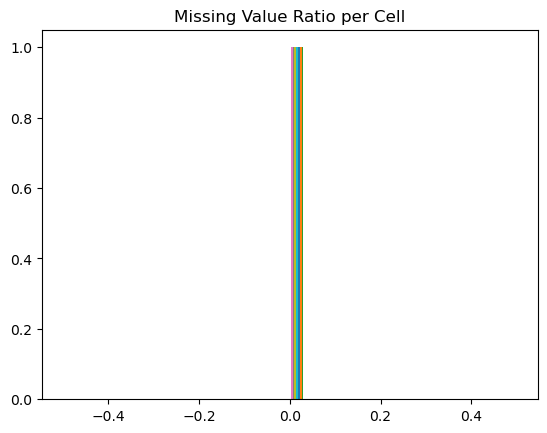

In [8]:
import matplotlib.pyplot as plt
no_call_ratio = (filtered_mtx == -1).mean(axis=0)
plt.hist(no_call_ratio, bins=30)
plt.title("Missing Value Ratio per Cell")

/Users/liqun/anaconda3/envs/singleCell/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


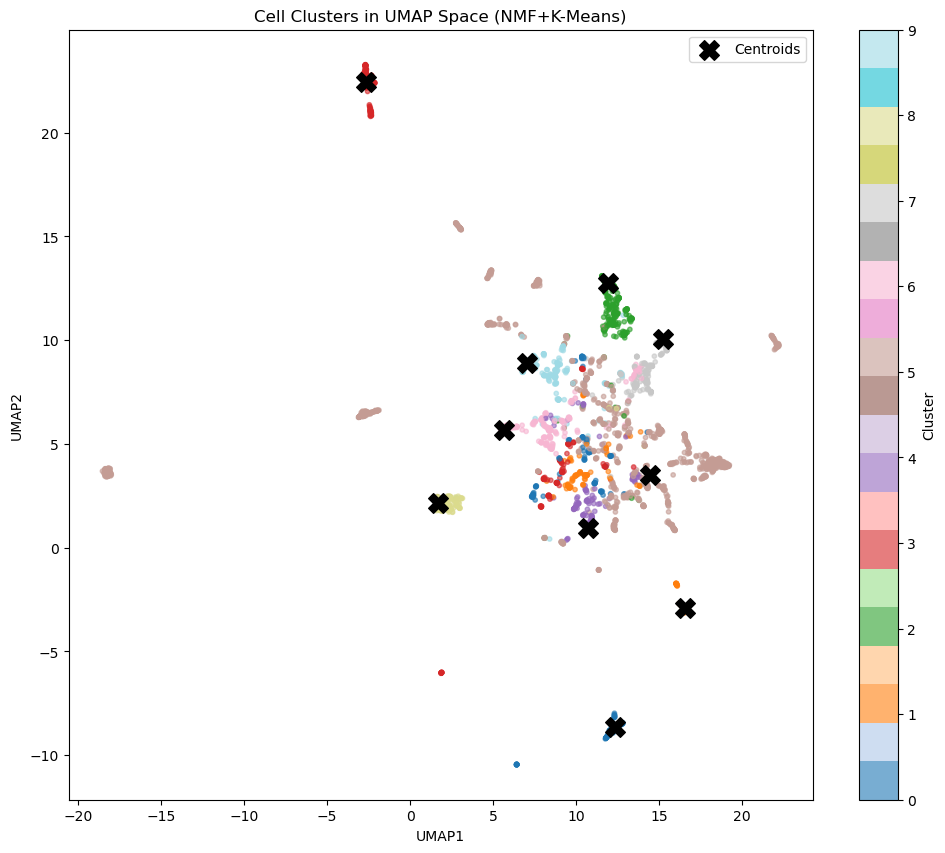

In [4]:
import numpy as np
import pandas as pd
from scipy import sparse
import matplotlib.pyplot as plt
from sklearn.decomposition import NMF
from sklearn.cluster import KMeans
import umap.umap_ as umap

# 转换为NMF可用的非负矩阵 (0/1/2)
nmf_input = filtered_mtx.copy().astype(np.float32)
nmf_input.data = nmf_input.data + 1  # -1→0, 0→1, 1→2

# NMF降维
n_components = 20  # 潜在特征数
nmf = NMF(n_components=n_components, 
          init='nndsvd', 
          random_state=42,
          max_iter=1000)
W = nmf.fit_transform(nmf_input.T)  # 细胞嵌入矩阵 [n_cells, n_components]
H = nmf.components_                # 突变特征矩阵 [n_components, n_mutations]

# K-Means聚类
kmeans = KMeans(n_clusters=10, random_state=42)
clusters = kmeans.fit_predict(W)

reducer = umap.UMAP(metric='cosine', random_state=42)
embedding = reducer.fit_transform(W)

plt.figure(figsize=(12, 10))
sc = plt.scatter(embedding[:, 0], embedding[:, 1],
                c=clusters, 
                s=10,
                cmap='tab20',
                alpha=0.6)
plt.colorbar(sc, label='Cluster')
plt.title("Cell Clusters in UMAP Space (NMF+K-Means)")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")

# 标记聚类中心
centers_umap = reducer.transform(kmeans.cluster_centers_)
plt.scatter(centers_umap[:, 0], centers_umap[:, 1],
           marker='X', s=200, c='black', label='Centroids')
plt.legend()
plt.show()

/Users/liqun/anaconda3/envs/singleCell/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


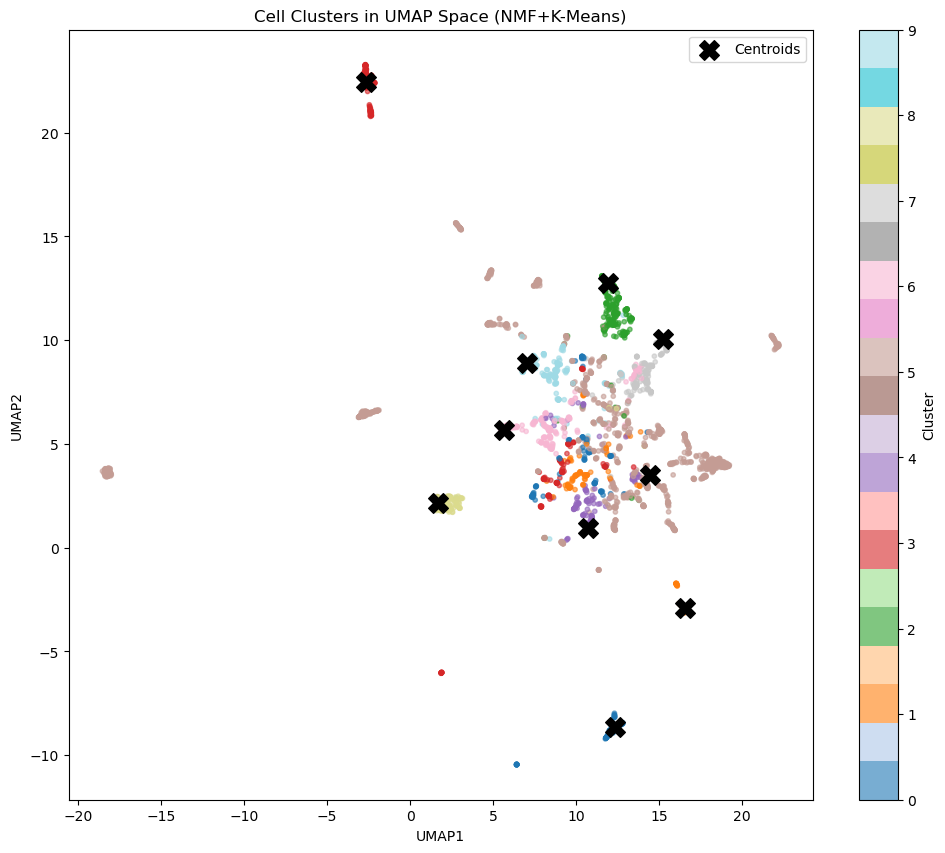

In [5]:
# UMAP降维
reducer = umap.UMAP(metric='cosine', random_state=42)
embedding = reducer.fit_transform(W)

plt.figure(figsize=(12, 10))
sc = plt.scatter(embedding[:, 0], embedding[:, 1],
                c=clusters, 
                s=10,
                cmap='tab20',
                alpha=0.6)
plt.colorbar(sc, label='Cluster')
plt.title("Cell Clusters in UMAP Space (NMF+K-Means)")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")

# 标记聚类中心
centers_umap = reducer.transform(kmeans.cluster_centers_)
plt.scatter(centers_umap[:, 0], centers_umap[:, 1],
           marker='X', s=200, c='black', label='Centroids')
plt.legend()
plt.show()

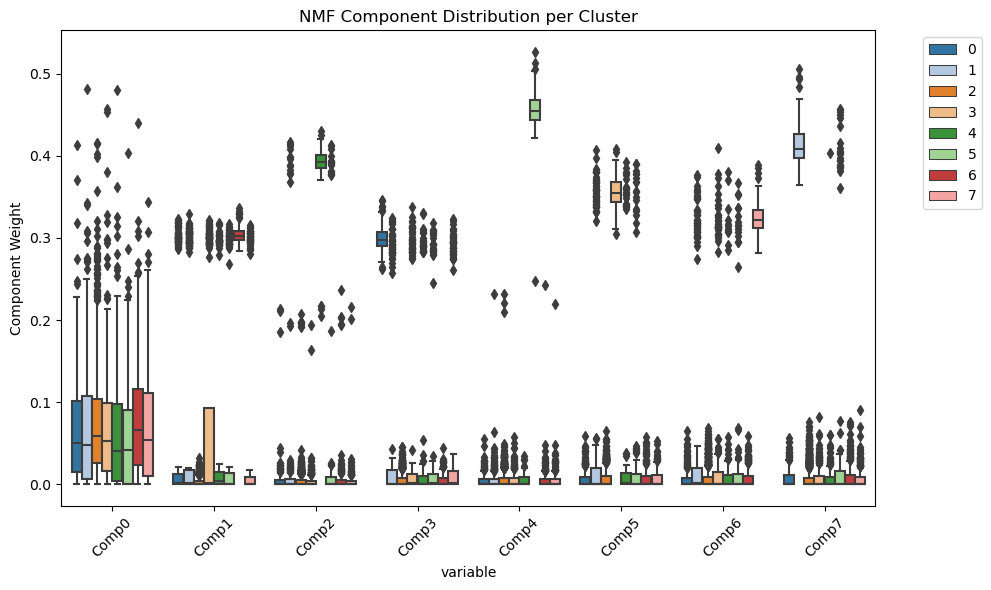

In [16]:
# 计算每个聚类在NMF组分上的平均权重
import seaborn as sns
cluster_components = pd.DataFrame(W, 
                                columns=[f"Comp{i}" for i in range(n_components)])
cluster_components['Cluster'] = clusters

plt.figure(figsize=(10, 6))
sns.boxplot(data=cluster_components.melt(id_vars='Cluster'),
            x='variable', y='value', hue='Cluster',
            palette='tab20')
plt.title("NMF Component Distribution per Cluster")
plt.xticks(rotation=45)
plt.ylabel("Component Weight")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

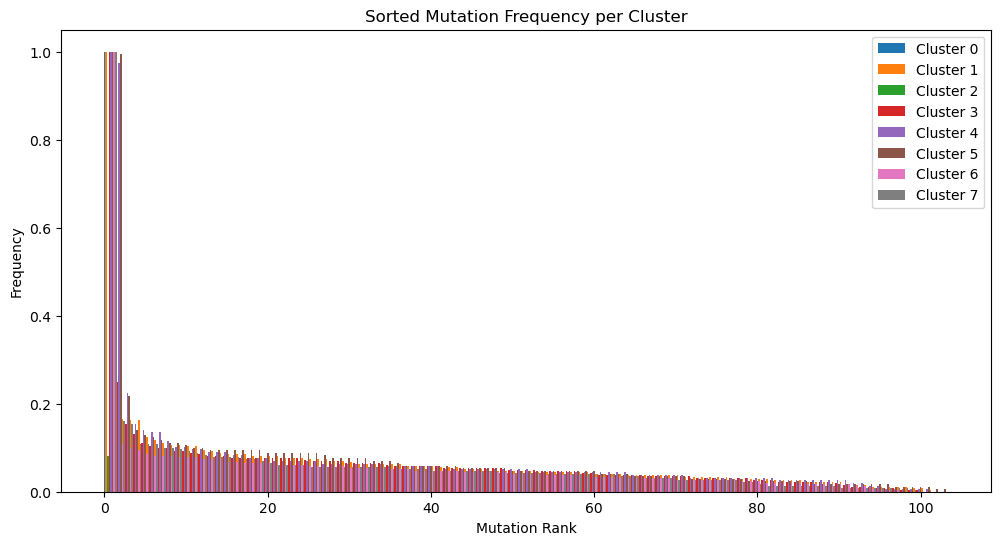

In [17]:
# 统计每个聚类的突变频率
cluster_mut_freq = []
for cl in np.unique(clusters):
    cells_in_cluster = (clusters == cl)
    freq = (filtered_mtx[:, cells_in_cluster] == 1).mean(axis=1).A1
    cluster_mut_freq.append(freq)

plt.figure(figsize=(12, 6))
for i, (cl, freqs) in enumerate(zip(np.unique(clusters), cluster_mut_freq)):
    plt.bar(np.arange(len(freqs)) + i*0.2, 
            np.sort(freqs)[::-1], 
            width=0.2, 
            label=f'Cluster {cl}')
plt.title("Sorted Mutation Frequency per Cluster")
plt.xlabel("Mutation Rank")
plt.ylabel("Frequency")
plt.legend()
plt.show()

/Users/liqun/anaconda3/envs/singleCell/lib/python3.10/site-packages/sklearn/decomposition/_nmf.py:1692: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


Text(0, 0.5, 'Error')

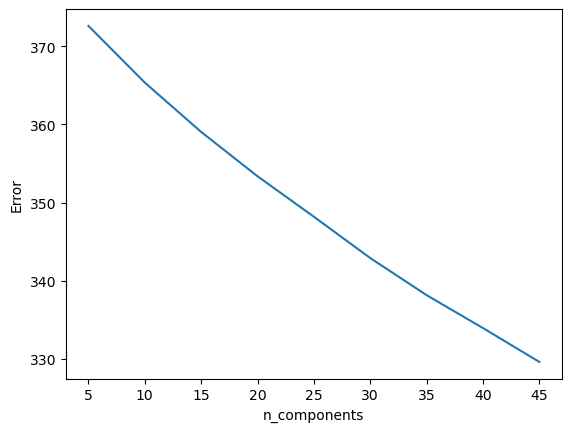

In [9]:
errors = []
for k in range(5, 50, 5):
    nmf = NMF(n_components=k, init='nndsvd')
    nmf.fit(nmf_input.T)
    errors.append(nmf.reconstruction_err_)
plt.plot(range(5, 50, 5), errors); plt.xlabel('n_components'); plt.ylabel('Error')

Text(0.5, 0, 'n_clusters')

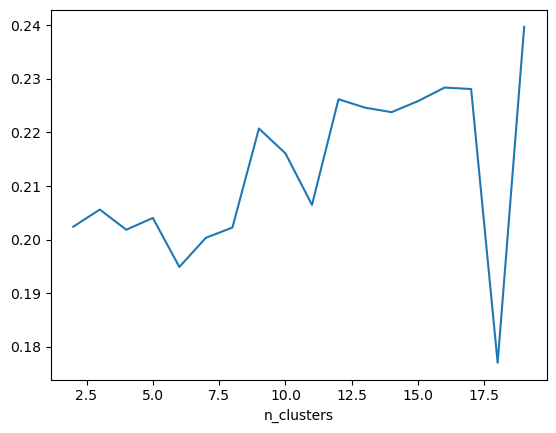

In [10]:
from sklearn.metrics import silhouette_score
scores = []
for k in range(2, 20):
    kmeans = KMeans(n_clusters=k)
    labels = kmeans.fit_predict(W)
    scores.append(silhouette_score(W, labels))
plt.plot(range(2, 20), scores); plt.xlabel('n_clusters')

In [6]:
import pandas as pd
results = pd.DataFrame({
    'Cell_ID': df.columns.tolist(),  # 从原始DataFrame获取细胞名
    'Cluster': clusters             # 聚类结果
})

# 保存为CSV
results.to_csv("/Users/liqun/scMutraceProject/Data/cellLine/epiAneufinder_results/scmutrace_cluster.csv", index=False)

In [ ]:
from collections import defaultdict
def modify_mutinfo(inputpath, outputpath):
    mutDic = defaultdict(list)
    print(">>> Processing input file")
    try:
        with open(inputpath, "r") as inputFile:
            for line in inputFile:
                fields = line.strip().split("\t")
                if len(fields) < 2:
                    continue
                try:
                    chrom, pos, ref_base, mut_base = fields[0].split("_")
                except ValueError:
                    print(f"Skipping line due to format issue: {line.strip()}")
                    continue
                loc = f"{chrom}_{pos}"
                if mut_base != ref_base:
                    if mut_base not in mutDic[loc]:
                        mutDic[loc].append(mut_base)
    except FileNotFoundError:
        print(f"Input file not found: {inputpath}")
        return
    print(mutDic)
    print(">>> Generating output")
    try:
        with open(outputpath, "w") as outputFile:
            with open(inputpath, "r") as inputFile:
                for line in inputFile:
                    fields = line.strip().split("\t")
                    if len(fields) < 2:
                        continue
                    try:
                        chrom, pos, ref_base, mut_base = fields[0].split("_")
                    except ValueError:
                        print(f"Skipping line due to format issue: {line.strip()}")
                        continue
                    loc = f"{chrom}_{pos}"
                    for mut in mutDic[loc]:
                        output_tag = f"{loc}_{ref_base}_{mut}"
                        if mut_base == mut:
                            status = "Mut"
                        else:
                            status = "WT"
                        outputFile.write(f"{output_tag}\t{fields[1]}\t{status}\n")
    except Exception as e:
        print(f"An error occurred while writing to the output file: {e}")

inputpath = "/Users/liqun/scMutraceProject/Data/GSE182109/test/test.txt"
outputpath = "/Users/liqun/scMutraceProject/Data/GSE182109/test/test.out.txt"
modify_mutinfo(inputpath, outputpath)

>>> Processing input file
defaultdict(<class 'list'>, {'chr9_72107817': ['A', 'C']})
>>> Generating output
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_72107817_G_C
Output tag: chr9_721078

observedMutRate: 0.08333333333333333
meanMutRate: 0.082
meanMutRate_simple: 0.07241666666666666
p-value: 9.999000099990002e-05


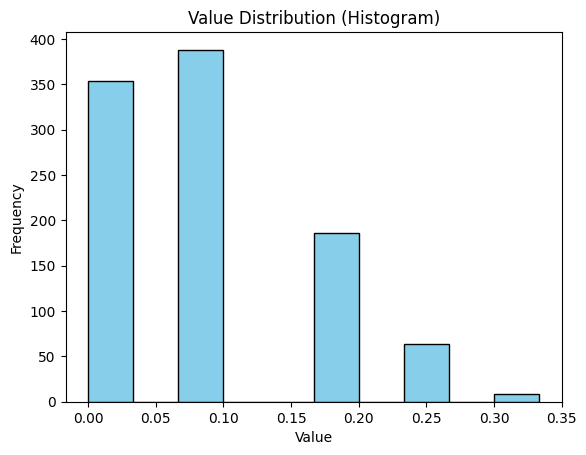

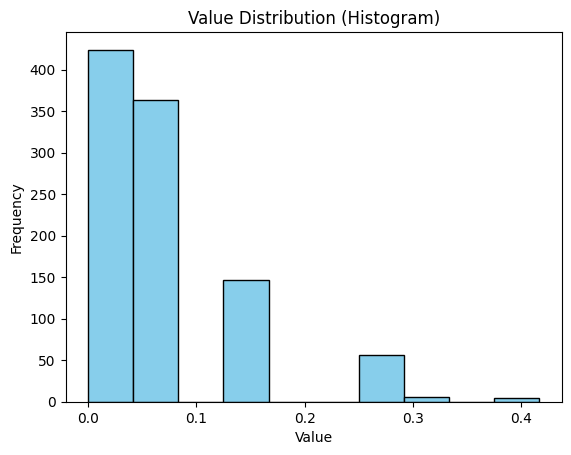

In [22]:
import random
from src.py_utils import *
from scipy.stats import permutation_test

def shuffle_reads_simple(baseQualityInfoOnesite, times):
    cells = baseQualityInfoOnesite.split(";")
    cell = random.choices(cells, k = times)
    return cell

import numpy as np
def statistic(x, y, axis=None):
    return np.mean(x, axis=axis) - np.mean(y, axis=axis)

resampleNum = 1000
refBase = "T"
baseQualityInfoOnesite = "|22||||;|41:41||||;|41||||;|32||||;|41||||;|41||||;|41:41||||;||37|||;|37||||;|41||||;|41||||;|37||||"


samples_random_baseQuaInfo = []
samples_random_baseQuaInfo_simple = []
samples_random_baseQuaInfo_simple = shuffle_reads_simple(baseQualityInfoOnesite, resampleNum)
readcountsNum, baseWeight, tmpDic, tmpDicP, readcountsWeight = shuffle_reads_features(refBase,baseQualityInfoOnesite)
#print("#####", readcountsNum, baseWeight, tmpDic, tmpDicP, readcountsWeight)
for i in range(0, resampleNum):
    sample_random_baseQuaInfo_tmp = shuffle_reads_baseonFeatures(readcountsNum, baseWeight, tmpDic, tmpDicP, readcountsWeight)
    samples_random_baseQuaInfo.append(sample_random_baseQuaInfo_tmp)

refNum, altNum = count_CellNum_fromQuainfo(refBase, baseQualityInfoOnesite)
total = refNum + altNum
observedMutRate = altNum / total
print("observedMutRate:", observedMutRate)
mutRateList = []
mutRateList_simple = []
for i in range(0, resampleNum):
    oneSiteBaseQuaList = random.sample(samples_random_baseQuaInfo, total)
    oneSiteBaseQua = ";".join(oneSiteBaseQuaList)
    refNum_tmp, altNum_tmp = count_CellNum_fromQuainfo(refBase, oneSiteBaseQua)
    total_tmp = refNum_tmp + altNum_tmp
    mutRate = altNum_tmp / total_tmp
    mutRateList.append(mutRate)

meanMutRate = np.mean(mutRateList)
print("meanMutRate:", meanMutRate)

for i in range(0, resampleNum):
    oneSiteBaseQuaList = random.sample(samples_random_baseQuaInfo_simple, total)
    oneSiteBaseQua = ";".join(oneSiteBaseQuaList)
    refNum_tmp, altNum_tmp = count_CellNum_fromQuainfo(refBase, oneSiteBaseQua)
    total_tmp = refNum_tmp + altNum_tmp
    mutRate = altNum_tmp / total_tmp
    mutRateList_simple.append(mutRate)

meanMutRate_simple = np.mean(mutRateList_simple)
print("meanMutRate_simple:", meanMutRate_simple)

mutRate_WT = [0] * 955 + [0.25] * 45
#random.shuffle(mutRate_WT)

res = permutation_test(
    (np.array(mutRateList), np.array(mutRate_WT)),
    statistic,
    vectorized=False,
    n_resamples=10000,
    alternative='greater'
)

print("p-value:", res.pvalue)

# plot mutation rate distribution and observed mutation rate
import matplotlib.pyplot as plt

plt.hist(mutRateList, bins=10, color='skyblue', edgecolor='black')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.title('Value Distribution (Histogram)')
plt.show()


plt.hist(mutRateList_simple, bins=10, color='skyblue', edgecolor='black')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.title('Value Distribution (Histogram)')
plt.show()


In [13]:
mutRate_WT = [0] * 955 + [0.25] * 45
print(mutRate_WT)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 

In [2]:
from src.py_utils import *
import os
import re
import timeit
import argparse
import multiprocessing as mp
import subprocess

def filter_snp_threeModel(VCFPath, outPath, a1, b1, a2, b2, model3ProbabilityDic, quainfos, iternum, errorP, backP, m1check, m2check, m3check):
    """
    Filters SNPs using a three-model approach and writes the results to an output file.

    Args:
        VCFPath (str): Path to the input VCF file.
        outPath (str): Path to the output file where filtered results will be written.
        a1 (float): Parameter a1 for the genotype assignment model.
        b1 (float): Parameter b1 for the genotype assignment model.
        a2 (float): Parameter a2 for the genotype assignment model.
        b2 (float): Parameter b2 for the genotype assignment model.
        model3ProbabilityDic (dict): Dictionary containing probabilities for the third model.
        quainfos (list): List of quality information.
        iternum (int): Number of iterations for the genotype assignment.
        errorP (float): Error probability.
        backP (float): Background probability.
        m1check (bool): Check flag for model 1.
        m2check (bool): Check flag for model 2.
        m3check (bool): Check flag for model 3.

    Raises:
        IndexError: If there is an indexing error while processing the VCF file.
        ValueError: If there is a value error while processing the VCF file.

    Returns:
        None
    """
    try:
        with open(VCFPath, "r") as vcfile, open(outPath, "w+") as outfile:
            fileRowNum = get_Vcf_rownum(VCFPath)
            counttmp = 0
            for line in vcfile:
                counttmp += 1
                if counttmp % 5000 == 0:
                    print("Processed " + str(counttmp) + "/" + str(fileRowNum) + " positions")
                lineSets = line.split("\t")
                refBase = lineSets[2]
                baseQualityInfoOnesite = lineSets[11]
                dptotal = int(lineSets[3])
                if dptotal <= 10:
                    testResult = assign_site_genotype(refBase, baseQualityInfoOnesite, a1, b1, a2, b2, False, model3ProbabilityDic, quainfos, 1000, iternum, errorP, backP, m1check, m2check, m3check)
                else:
                    testResult = assign_site_genotype(refBase, baseQualityInfoOnesite, a1, b1, a2, b2, True, model3ProbabilityDic, quainfos, 1000, iternum, errorP, backP, m1check, m2check, m3check)
                filterinfo = ";".join([str(testResult["m1"]), str(testResult["m2"]), str(testResult["m3"])])
                statpvalue = ";".join([str(testResult["p1"]), str(testResult["p2"]), str(testResult["p3"])])
                iteresampleNum = ";".join([str(testResult["ic1"]), str(testResult["ic2"]), str(testResult["ic3"]), str(iternum)])
                filtercheck = "NonePASS"
                supportEvidence = "NoneSupport"
                if testResult["m1"] + testResult["m2"] + testResult["m3"] >= 1:
                    filtercheck = "PASS_3Model"
                    supportEvidence = "Strong"
                if filtercheck == "NonePASS" and (testResult["c1"] + testResult["c2"] + testResult["c3"]) >= 1:
                    supportEvidence = "Weak"
                    filtercheck = "PASS_3Model"
                sql = line.strip() + "\t" + filterinfo + "\t" + filtercheck + "\t" + statpvalue + "\t" + supportEvidence + "\t" + iteresampleNum
                outfile.writelines(sql + "\n")
                outfile.flush()
            print("Done for " + VCFPath)
            cmd = ["rm", VCFPath]
            try:
                subprocess.run(cmd, check=True)
            except subprocess.CalledProcessError as e:
                print(f"An error occurred while executing command: {e.cmd}")
                print(f"Return code: {e.returncode}")
                print(f"Output: {e.output}")
    except (IndexError, ValueError) as e:
        print(f"An error occurred: {e}")

a1 = 0.0056773121
b1 = 1.3777933664
a2 = 0.0098542673
b2 = 1.6730916145
errorP = 0.006
backP = 0.045
quainfos = list(range(20, 60, 1))
iternum = 1000
m1check = True
m2check = False
m3check = False

model3ProbabilityDic = create_model3_probabilityDic(errorP)


filter_snp_threeModel("/Users/liqun/Downloads/splitVcf_VCF_PBMC_tenx_2.vcfaa", "/Users/liqun/Downloads/PBMC_tenx_2.vcfac_filter.vcf", a1, b1, a2, b2, model3ProbabilityDic, quainfos, iternum, errorP, backP, m1check, m2check, m3check)




Processed 5000/30895 positions
Processed 10000/30895 positions
Processed 15000/30895 positions
Processed 20000/30895 positions
Processed 25000/30895 positions
Processed 30000/30895 positions
Done for /Users/liqun/Downloads/splitVcf_VCF_PBMC_tenx_2.vcfaa


In [3]:
filter_snp_threeModel("/Users/liqun/Downloads/splitVcf_VCF_PBMC_tenx_6.vcfaa", "/Users/liqun/Downloads/PBMC_tenx_6.vcfac_filter.vcf", a1, b1, a2, b2, model3ProbabilityDic, quainfos, iternum, errorP, backP, m1check, m2check, m3check)

Processed 5000/25758 positions
Processed 10000/25758 positions
Processed 15000/25758 positions
Processed 20000/25758 positions
Processed 25000/25758 positions
Done for /Users/liqun/Downloads/splitVcf_VCF_PBMC_tenx_6.vcfaa


In [ ]:
import os
import re
import subprocess
def merge_filteredVcf_file(sampleID, filteredVcfPaths, dirPath):
    """
    Merges filtered VCF files for a given sample ID and chromosome, and removes the original files.

    Args:
        sampleID (str): The sample ID used to identify the VCF files.
        filteredVcfPaths (list of str): List of paths to the filtered VCF files.
        dirPath (str): Directory path where the merged VCF files will be saved.

    Raises:
        subprocess.CalledProcessError: If an error occurs while executing the shell commands.
    """
    chrs = list(set([i.split(sampleID + "_")[1].split(".")[0] for i in filteredVcfPaths]))
    for chr in chrs:
        tmpipaths = [j for j in filteredVcfPaths if re.search(sampleID + "_" + str(chr) + ".vcf", j) != None]
        tmpsql = " ".join(tmpipaths)
        cmdmerge = f"cat {tmpsql} > {dirPath}{sampleID}_{chr}_filter.vcf"
        cmdrm = f"rm {tmpsql}"
        try:
            subprocess.run(cmdmerge, shell=True, check=True)
            subprocess.run(cmdrm, shell=True, check=True)
        except subprocess.CalledProcessError as e:
            print(f"An error occurred while executing command: {e.cmd}")
            print(f"Return code: {e.returncode}")
            print(f"Output: {e.output}")

sampleID = "PBMC_tenx"
filteredVcfPaths = ["/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_10.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_14.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_18.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_21.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_3.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_6.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_8.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_11.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_15.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_19.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_22.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_3.vcfab_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_6.vcfab_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_9.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_12.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_16.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_1.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_2.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_4.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_6.vcfac_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_X.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_12.vcfab_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_17.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_1.vcfab_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_2.vcfab_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_5.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_7.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_Y.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_13.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_17.vcfab_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_20.vcfaa_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_2.vcfac_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_5.vcfab_filter.vcf", "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/PBMC_tenx_7.vcfab_filter.vcf"]
dirPath = "/cfs/klemming/home/q/qunli/qunr/smartSeq10X/10x/PBMC_tenx/scMutrace/filterVCF/"
merge_filteredVcf_file(sampleID, filteredVcfPaths, dirPath)